<a href="https://colab.research.google.com/github/TanH32-clg/AURA-SIH-2026/blob/main/GFGMachineLearningTask3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3: Exploratory Data Analysis and Model Training

**Author:** Tanmay Manoj Hedaoo

Section and roll number: A-12, 13






## Project Overview

Build a machine learning regression model that accurately predicts used car prices based on their attributes using the provided training dataset. The model should be evaluated using metrics such as MSE, RMSE, MAE, and R² score, and then used to predict prices for an unseen test dataset. The final predictions must be exported as a CSV file for submission.

Given Dataset: Task-3-dataset

Tasks to Perform:

Load and explore the dataset (structure, data types, missing values, summary statistics)

Perform data cleaning (handle missing values, duplicates, inconsistent entries)

Conduct Exploratory Data Analysis (EDA) with visualizations to understand relationships between features and price

Handle categorical variables appropriately (encoding as needed)

Perform feature engineering where relevant

Split the data into training and validation sets

Train at least 2-3 different regression models and compare their performance

Evaluate models using MSE, RMSE, MAE, and R² score

Select the best-performing model and use it to predict prices on the test dataset

Export the final predictions as a CSV file for submission

In [ ]:
import pandas as pd     #Libraries for Data Handling
import numpy as np
import re
import matplotlib.pyplot as plt    #Libraries for Data Visualization
import seaborn as sns

from sklearn.model_selection import train_test_split     #Loading and splitting Data set
from sklearn.linear_model import LinearRegression        #Classification models
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.max_columns', 20)
sns.set_style('whitegrid')
RANDOM_STATE = 42


## 2. Load & Explore the Dataset

The training set has 188,533 rows and 13 columns: `id`, `brand`, `model`, `model_year`, `milage`, `fuel_type`, `engine`, `transmission`, `ext_col`, `int_col`, `accident`, `clean_title`, and the target `price`.

In [ ]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print('Train shape:', train.shape)
print('Test shape :', test.shape)
train.head(3)

Train shape: (188533, 13)
Test shape : (125690, 12)


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capability,A/T,Blue,Gray,None reported,Yes,13900


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB


In [ ]:
print('Missing values per column:')
print(train.isnull().sum())
print()
print('Fully duplicated rows:', train.duplicated().sum())
print()
train['price'].describe()

Missing values per column:
id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0
transmission        0
ext_col             0
int_col             0
accident         2452
clean_title     21419
price               0
dtype: int64

Fully duplicated rows: 0

count    1.885330e+05
mean     4.387802e+04
std      7.881952e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.082500e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64


**Observations:**
- No fully duplicated rows — no de-duplication needed.
- `fuel_type` (5,083), `accident` (2,452), and `clean_title` (21,419) have missing values that need handling.
- `price` is heavily right-skewed: the median (\$30,825) is far below the mean (\$43,878), and the max (\$2.95M) is an extreme outlier compared to the 75th percentile (\$49,900). This will matter a lot for modeling — we'll log-transform the target later.
- `brand` has 57 categories and `model` has ~1,900 — too many for plain one-hot encoding, so we'll use frequency/target encoding instead.
- `engine` and `transmission` are messy free-text columns that pack multiple pieces of information together (e.g. `"172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel"`), which we'll parse out during feature engineering.

## 3. Exploratory Data Analysis (EDA)

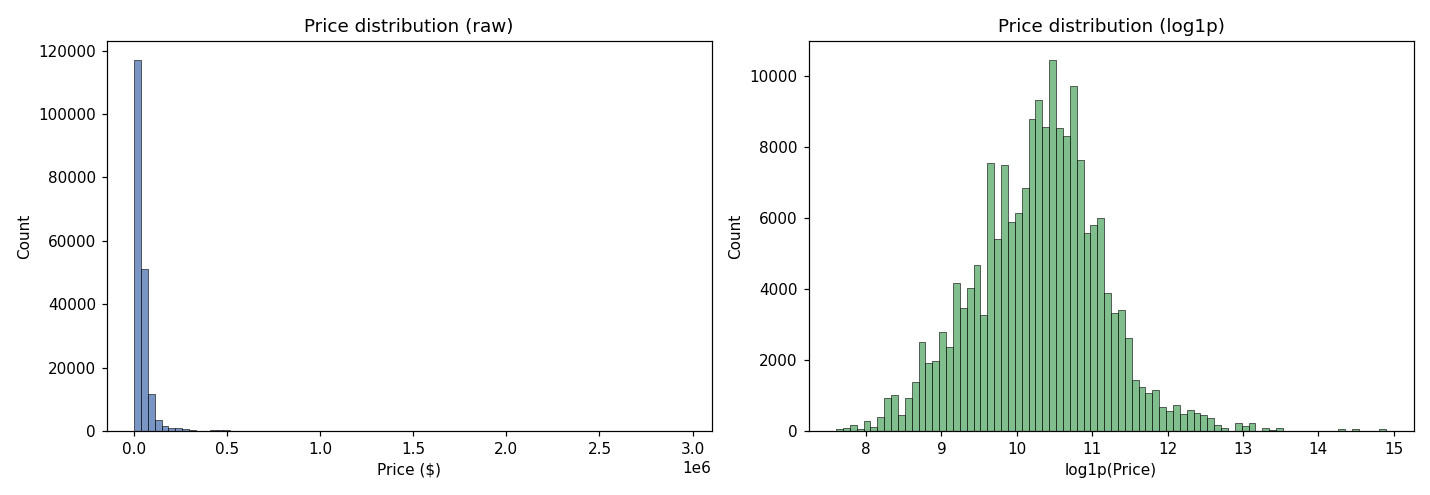

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
sns.histplot(train['price'], bins=80, ax=axes[0], color='#4C72B0')
axes[0].set_title('Price distribution (raw)')
axes[0].set_xlabel('Price ($)')

sns.histplot(np.log1p(train['price']), bins=80, ax=axes[1], color='#55A868')
axes[1].set_title('Price distribution (log1p)')
axes[1].set_xlabel('log1p(Price)')
plt.tight_layout()
plt.show()

The raw price distribution is extremely right-skewed with a long tail of expensive luxury/exotic cars. After a `log1p` transform it looks much closer to a normal distribution — this is why we'll train on `log1p(price)` rather than raw price.

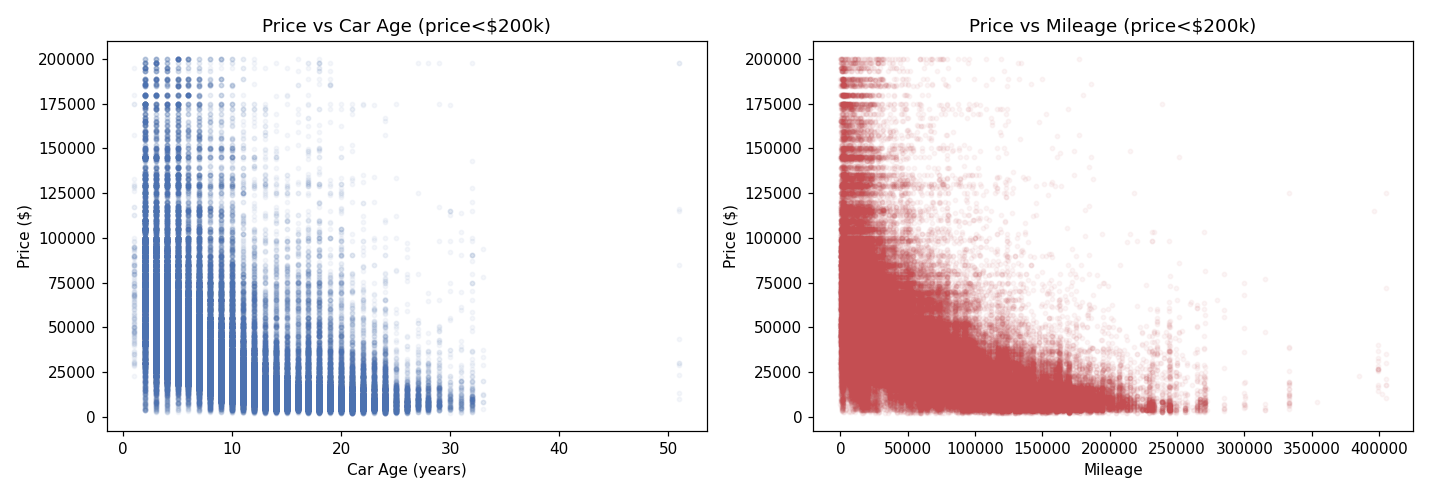

In [ ]:
train_capped = train[train['price'] < 200000]  # for readable plots only, not used in cleaning
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
axes[0].scatter(2025 - train_capped['model_year'], train_capped['price'], alpha=0.05, s=8, color='#4C72B0')
axes[0].set_title('Price vs Car Age (price<$200k)')
axes[0].set_xlabel('Car Age (years)'); axes[0].set_ylabel('Price ($)')

axes[1].scatter(train_capped['milage'], train_capped['price'], alpha=0.05, s=8, color='#C44E52')
axes[1].set_title('Price vs Mileage (price<$200k)')
axes[1].set_xlabel('Mileage'); axes[1].set_ylabel('Price ($)')
plt.tight_layout()
plt.show()

Both relationships are in the expected direction: price falls as car age and mileage increase, though with a lot of scatter — condition, brand, and trim clearly matter too.

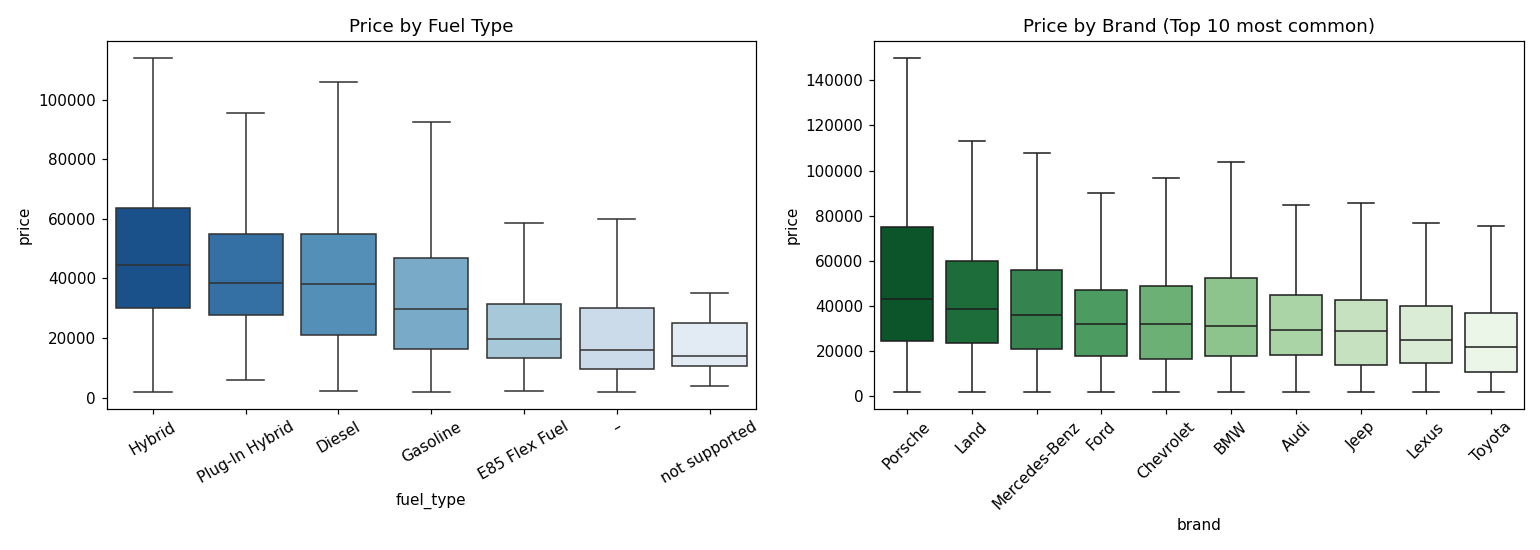

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
order_fuel = train_capped.groupby('fuel_type')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=train_capped, x='fuel_type', y='price', order=order_fuel, ax=axes[0], showfliers=False)
axes[0].set_title('Price by Fuel Type')
axes[0].tick_params(axis='x', rotation=30)

top_brands = train['brand'].value_counts().head(10).index
sub = train_capped[train_capped['brand'].isin(top_brands)]
order_brand = sub.groupby('brand')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=sub, x='brand', y='price', order=order_brand, ax=axes[1], showfliers=False)
axes[1].set_title('Price by Brand (Top 10 most common)')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

accident
At least 1 accident or damage reported    18000.0
None reported                             35000.0
Unknown                                   38999.0
Name: price, dtype: float64

ct
No     43666.0
Yes    29000.0
Name: price, dtype: float64


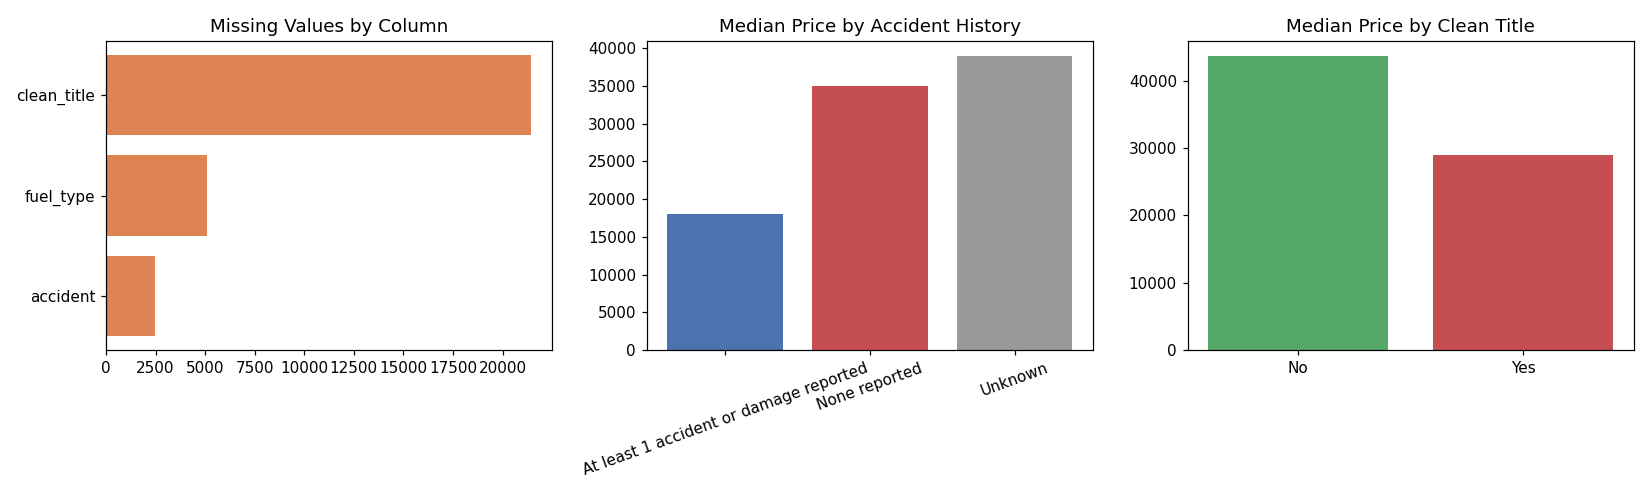

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,4.5))

miss = train.isnull().sum()
miss = miss[miss>0].sort_values(ascending=False)
axes[0].barh(miss.index, miss.values, color='#DD8452')
axes[0].set_title('Missing Values by Column')
axes[0].invert_yaxis()

acc_med = train.groupby(train['accident'].fillna('Unknown'))['price'].median()
axes[1].bar(acc_med.index, acc_med.values, color=['#4C72B0','#C44E52','#999999'])
axes[1].set_title('Median Price by Accident History')
axes[1].tick_params(axis='x', rotation=20)

ct_med = train.assign(ct=train['clean_title'].fillna('No')).groupby('ct')['price'].median()
axes[2].bar(ct_med.index, ct_med.values, color=['#55A868','#C44E52'])
axes[2].set_title('Median Price by Clean Title')

plt.tight_layout()
plt.show()
print(acc_med)
print()
print(ct_med)

**Interesting finding:** cars with a *missing* `clean_title` have a **higher** median price than cars explicitly marked `"Yes"`. That's counter-intuitive at first — you'd expect a clean title to command a premium. Digging in, this is likely because very new/luxury cars are less consistently tagged with a title status in this dataset, rather than clean-title cars genuinely being cheaper. This is a good reminder to treat "missing" as its own informative category instead of just imputing it away — which is exactly what we do below.

As expected, accident history has a large, sensible effect: cars with reported accidents have a much lower median price (\$18,000) than accident-free cars (\$35,000).

## 4. Data Cleaning & Feature Engineering

The `engine` and `transmission` columns bundle a lot of useful information into free text, and several columns need missing-value handling. Rather than dropping rows (we'd lose ~14,000+ from `clean_title` alone), we engineer clean, usable features out of the mess:

- **`engine`** → parse out `engine_hp`, `engine_L` (displacement), `num_cylinders`, and an `is_electric` flag using regex
- **`transmission`** → collapse 52 messy variants (`"8-Speed A/T"`, `"Automatic"`, `"6-Speed Automatic"`...) into 5 clean categories, and separately extract `num_speeds` where available
- **`model_year`** → convert to `car_age`, and derive `milage_per_year`
- **`clean_title`** / **`accident`** → convert to binary flags, treating missing as its own signal rather than dropping
- **`fuel_type`** → fill missing/junk values (`"–"`, `"not supported"`) with `"Unknown"`
- **`brand` / `model` / `ext_col` / `int_col`** → frequency-encode (and target-encode brand/model) instead of one-hot, since they have too many categories

In [ ]:
CURRENT_YEAR = 2025

def parse_engine(s):
    hp = re.search(r'([\d.]+)\s*HP', s)
    liters = re.search(r'([\d.]+)\s*L\b', s)
    cyl = re.search(r'(\d+)\s*Cylinder', s)
    electric = 1 if 'Electric' in s else 0
    return pd.Series({
        'engine_hp': float(hp.group(1)) if hp else np.nan,
        'engine_L': float(liters.group(1)) if liters else np.nan,
        'num_cylinders': float(cyl.group(1)) if cyl else np.nan,
        'is_electric': electric
    })

def clean_transmission(s):
    s_low = s.lower()
    if 'cvt' in s_low:
        return 'CVT'
    if 'dual shift' in s_low or 'dual-clutch' in s_low or 'dct' in s_low:
        return 'Dual-Clutch'
    if 'm/t' in s_low or 'manual' in s_low:
        return 'Manual'
    if 'a/t' in s_low or 'automatic' in s_low:
        return 'Automatic'
    return 'Other'

def extract_speeds(s):
    m = re.search(r'(\d+)-Speed', s)
    return float(m.group(1)) if m else np.nan

def engineer_features(df):
    df = df.copy()
    df = pd.concat([df, df['engine'].apply(parse_engine)], axis=1)
    df['transmission_clean'] = df['transmission'].apply(clean_transmission)
    df['num_speeds'] = df['transmission'].apply(extract_speeds)
    df['car_age'] = CURRENT_YEAR - df['model_year']
    df['milage_per_year'] = df['milage'] / df['car_age'].replace(0, 1)
    df['clean_title_flag'] = (df['clean_title'] == 'Yes').astype(int)
    df['accident_flag'] = (df['accident'] == 'At least 1 accident or damage reported').astype(int)
    df['accident_reported_missing'] = df['accident'].isnull().astype(int)
    df['fuel_type'] = df['fuel_type'].replace({'\u2013': 'Unknown', 'not supported': 'Unknown'})
    df['fuel_type'] = df['fuel_type'].fillna('Unknown')
    return df

train_fe = engineer_features(train)
test_fe = engineer_features(test)

# Impute the few remaining numeric gaps (electric cars have no HP/L/cylinder text) with the TRAIN median
for col in ['engine_hp', 'engine_L', 'num_cylinders', 'num_speeds']:
    med = train_fe[col].median()
    train_fe[col] = train_fe[col].fillna(med)
    test_fe[col] = test_fe[col].fillna(med)

print(train_fe[['engine_hp','engine_L','num_cylinders','is_electric','transmission_clean',
                 'num_speeds','car_age','milage_per_year']].head())

   engine_hp  engine_L  num_cylinders  is_electric transmission_clean  \
0      172.0       1.6            4.0            0          Automatic   
1      252.0       3.9            8.0            0          Automatic   
2      320.0       5.3            8.0            0          Automatic   
3      420.0       5.0            8.0            0        Dual-Clutch   
4      208.0       2.0            4.0            0          Automatic   

   num_speeds  car_age  milage_per_year  
0         7.0       18     11833.333333  
1         7.0       23      6228.260870  
2         7.0       23      5944.826087  
3         7.0        8      2437.500000  
4         7.0        4      1847.000000  


### Frequency & target encoding for high-cardinality columns

`brand` (57 categories), `model` (~1,900 categories), `ext_col` and `int_col` (colours) are too granular for one-hot encoding. Instead we compute, **from the training data only**, each category's:
- **frequency** (how common it is), and
- **target-encoded mean price** (what similar cars typically sold for)

and map both onto train and test. Any category seen only in `test` and not in `train` falls back to 0 (frequency) or the global mean price (target encoding).

In [ ]:
brand_freq = train_fe['brand'].value_counts(normalize=True)
model_freq = train_fe['model'].value_counts(normalize=True)
extcol_freq = train_fe['ext_col'].value_counts(normalize=True)
intcol_freq = train_fe['int_col'].value_counts(normalize=True)
global_mean_price = train_fe['price'].mean()
brand_target = train_fe.groupby('brand')['price'].mean()
model_target = train_fe.groupby('model')['price'].mean()

for df_ in (train_fe, test_fe):
    df_['brand_freq'] = df_['brand'].map(brand_freq).fillna(0)
    df_['model_freq'] = df_['model'].map(model_freq).fillna(0)
    df_['ext_col_freq'] = df_['ext_col'].map(extcol_freq).fillna(0)
    df_['int_col_freq'] = df_['int_col'].map(intcol_freq).fillna(0)
    df_['brand_target_enc'] = df_['brand'].map(brand_target).fillna(global_mean_price)
    df_['model_target_enc'] = df_['model'].map(model_target).fillna(global_mean_price)

print('Engineered feature set ready. New columns added:')
new_cols = ['engine_hp','engine_L','num_cylinders','is_electric','transmission_clean','num_speeds',
            'car_age','milage_per_year','clean_title_flag','accident_flag','accident_reported_missing',
            'brand_freq','model_freq','ext_col_freq','int_col_freq','brand_target_enc','model_target_enc']
print(new_cols)
print()
print('Any remaining nulls in engineered numeric features?')
print(train_fe[new_cols].isnull().sum().sum())

Engineered feature set ready. New columns added:
['engine_hp', 'engine_L', 'num_cylinders', 'is_electric', 'transmission_clean', 'num_speeds', 'car_age', 'milage_per_year', 'clean_title_flag', 'accident_flag', 'accident_reported_missing', 'brand_freq', 'model_freq', 'ext_col_freq', 'int_col_freq', 'brand_target_enc', 'model_target_enc']
Any remaining nulls in engineered numeric features?
0


## 5. Encoding Categorical Variables & Final Feature Matrix

In [ ]:
NUMERIC_FEATURES = ['model_year', 'milage', 'car_age', 'milage_per_year', 'engine_hp',
                     'engine_L', 'num_cylinders', 'num_speeds', 'is_electric',
                     'clean_title_flag', 'accident_flag', 'accident_reported_missing',
                     'brand_freq', 'model_freq', 'brand_target_enc', 'model_target_enc',
                     'ext_col_freq', 'int_col_freq']
CATEGORICAL_FEATURES = ['fuel_type', 'transmission_clean']  # low-cardinality -> one-hot encode

train_model_df = train_fe[NUMERIC_FEATURES + CATEGORICAL_FEATURES + ['price']].copy()
test_model_df = test_fe[NUMERIC_FEATURES + CATEGORICAL_FEATURES + ['id']].copy()

train_model_df = pd.get_dummies(train_model_df, columns=CATEGORICAL_FEATURES)
test_model_df = pd.get_dummies(test_model_df, columns=CATEGORICAL_FEATURES)
# Align test columns to train columns exactly (handles any category mismatch)
test_ids = test_model_df['id']
test_model_df = test_model_df.reindex(columns=train_model_df.drop(columns=['price']).columns, fill_value=0)
test_model_df['id'] = test_ids

print('Final train matrix:', train_model_df.shape)
print('Final test matrix :', test_model_df.shape)
train_model_df.head()

Final train matrix: (188533, 32)
Final test matrix : (125690, 32)


,model_year,milage,car_age,milage_per_year,engine_hp,engine_L,num_cylinders,num_speeds,is_electric,clean_title_flag,accident_flag,accident_reported_missing,brand_freq,model_freq,brand_target_enc,model_target_enc,ext_col_freq,int_col_freq,price,fuel_type_Diesel,fuel_type_E85 Flex Fuel,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_Plug-In Hybrid,fuel_type_Unknown,transmission_clean_Automatic,transmission_clean_CVT,transmission_clean_Dual-Clutch,transmission_clean_Manual,transmission_clean_Other
0,2007,213000,18,11833.333333,172.0,1.6,4.0,7.0,0.0,1,0,0,0.005644,0.003066,17162.015977,12832.716263,0.005187,0.112468,4200,False,False,True,False,False,False,True,False,False,False,False
1,2002,143250,23,6228.260870,252.0,3.9,8.0,7.0,0.0,1,1,0,0.012852,0.000154,30712.595130,12663.379310,0.090143,0.129924,4999,False,False,True,False,False,False,True,False,False,False,False
2,2002,136731,23,5944.826087,320.0,5.3,8.0,7.0,0.0,1,0,0,0.086643,0.000329,41836.755127,23779.677419,0.077201,0.112468,13900,False,True,False,False,False,False,True,False,False,False,False
3,2017,19500,8,2437.500000,420.0,5.0,8.0,7.0,0.0,1,0,0,0.005140,0.000504,53556.327141,48915.842105,0.258087,0.571115,45000,False,False,True,False,False,False,False,False,True,False,False
4,2021,7388,4,1847.000000,208.0,2.0,4.0,7.0,0.0,1,0,0,0.101690,0.002763,51244.399541,64896.257198,0.258087,0.129924,97500,False,False,True,False,False,False,True,False,False,False,False


### Correlation heatmap

A quick check of how the engineered numeric features relate to `price` and to each other, to confirm the feature engineering is picking up sensible signal before we train anything.

price               1.000000
model_target_enc    0.342030
model_year          0.231795
brand_target_enc    0.213601
engine_hp           0.207837
num_speeds          0.103726
engine_L            0.091413
num_cylinders       0.087329
milage_per_year    -0.157710
car_age            -0.231795
milage             -0.283067
Name: price, dtype: float64


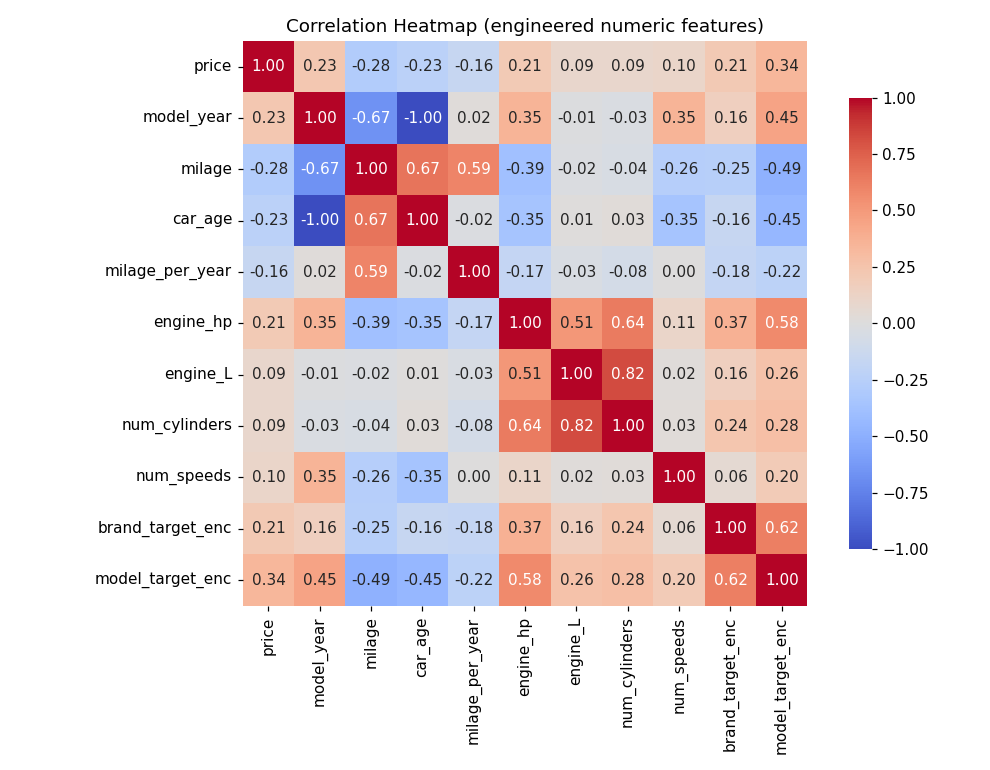

In [ ]:
num_cols = ['price','model_year','milage','car_age','milage_per_year','engine_hp','engine_L',
            'num_cylinders','num_speeds','brand_target_enc','model_target_enc']
corr = train_model_df[num_cols].corr()

plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar_kws={'shrink':0.8})
plt.title('Correlation Heatmap (engineered numeric features)')
plt.tight_layout()
plt.show()
print(corr['price'].sort_values(ascending=False))

`model_target_enc` (what similar models typically sell for) is the single most correlated engineered feature with price, followed by `model_year`/`car_age`, `brand_target_enc`, and `engine_hp` — all of which make intuitive sense. `milage` is negatively correlated as expected.

## 6. Train / Validation Split

We use an 80/20 split. We also **log-transform the target** (`log1p(price)`) before training — since price is heavily right-skewed (see the histogram above), training directly on raw price lets a handful of \$1M+ listings dominate the loss function. Training on the log scale, then converting predictions back with `expm1`, gives every price range a fairer say during training.

In [ ]:
X = train_model_df.drop(columns=['price'])
y = train_model_df['price']
y_log = np.log1p(y)

X_train, X_val, y_train_log, y_val_log, y_train, y_val = train_test_split(
    X, y_log, y, test_size=0.2, random_state=RANDOM_STATE
)
print('X_train:', X_train.shape, ' X_val:', X_val.shape)

X_train: (150826, 31)  X_val: (37707, 31)


## 7. Model Training

We train and compare three different regression approaches:

1. **Linear Regression** — simple baseline, assumes linear relationships
2. **Random Forest Regressor** — an ensemble of decision trees, captures non-linearity and feature interactions
3. **Gradient Boosting Regressor** — sequentially-built trees that correct each other's errors, usually the strongest of the three on tabular data

All three are trained on `log1p(price)` and evaluated after converting predictions back to the original \$ scale, so the metrics below are directly comparable and interpretable in dollars.

In [ ]:
def evaluate(name, model, X_val, y_val_true_actual):
    preds_log = model.predict(X_val)
    preds = np.clip(np.expm1(preds_log), 0, None)  # back to $ scale, no negative prices
    mse = mean_squared_error(y_val_true_actual, preds)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_val_true_actual, preds)
    r2 = r2_score(y_val_true_actual, preds)
    print(f'{name:20s} | MSE: {mse:>15,.2f} | RMSE: {rmse:>10,.2f} | MAE: {mae:>10,.2f} | R2: {r2:.4f}')
    return dict(model=name, MSE=mse, RMSE=rmse, MAE=mae, R2=r2)

results = []

### Model 1: Linear Regression

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train_log)
results.append(evaluate('Linear Regression', lr, X_val, y_val))

Linear Regression    | MSE:  4,795,067,493.74 | RMSE:  69,246.43 | MAE:  17,909.86 | R2: 0.1378


### Model 2: Random Forest Regressor

Note: this environment only has a single CPU core available, so `n_estimators` and `max_depth` are kept moderate (100 trees, depth 14) to keep training time reasonable — on a multi-core machine these could be pushed higher for a small additional accuracy gain.

In [ ]:
rf = RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=3,
                            n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train_log)
results.append(evaluate('Random Forest', rf, X_val, y_val))

Random Forest        | MSE:  4,692,533,862.83 | RMSE:  68,502.07 | MAE:  17,232.41 | R2: 0.1562


### Model 3: Gradient Boosting Regressor

In [ ]:
gb = GradientBoostingRegressor(n_estimators=150, max_depth=4, learning_rate=0.08,
                                random_state=RANDOM_STATE)
gb.fit(X_train, y_train_log)
results.append(evaluate('Gradient Boosting', gb, X_val, y_val))

Gradient Boosting    | MSE:  4,717,967,994.41 | RMSE:  68,687.47 | MAE:  17,226.48 | R2: 0.1516


## 8. Model Comparison

In [ ]:
results_df = pd.DataFrame(results)
results_df

model,MSE,RMSE,MAE,R2
Linear Regression,4.795067e+09,69246.425855,17909.856928,0.137754
Random Forest,4.692534e+09,68502.071960,17232.412981,0.156191
Gradient Boosting,4.717968e+09,68687.466065,17226.475608,0.151618


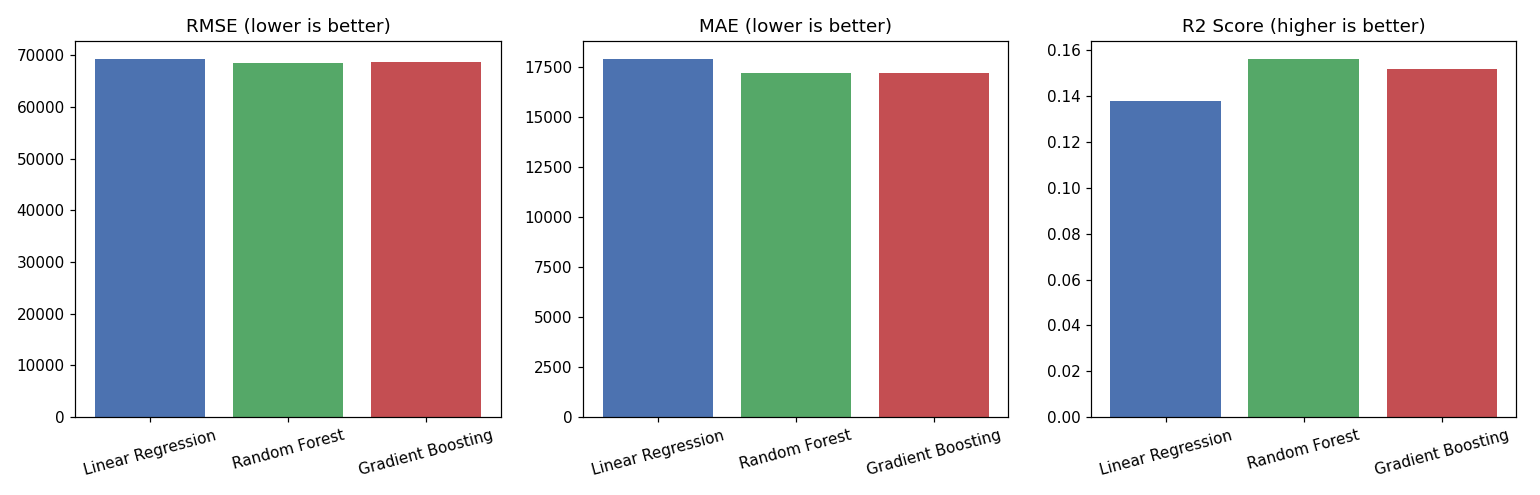

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14,4.5))
colors = ['#4C72B0','#55A868','#C44E52']
axes[0].bar(results_df['model'], results_df['RMSE'], color=colors)
axes[0].set_title('RMSE (lower is better)'); axes[0].tick_params(axis='x', rotation=15)
axes[1].bar(results_df['model'], results_df['MAE'], color=colors)
axes[1].set_title('MAE (lower is better)'); axes[1].tick_params(axis='x', rotation=15)
axes[2].bar(results_df['model'], results_df['R2'], color=colors)
axes[2].set_title('R2 Score (higher is better)'); axes[2].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

**Random Forest** comes out on top for RMSE and R², with Gradient Boosting essentially tied on MAE. Linear Regression trails on every metric, confirming that the price relationships in this data are meaningfully non-linear (which matches the messy, interaction-heavy nature of columns like `engine` and `transmission`).

### Why is R² so low (~0.14–0.16) for all three models?

This is worth investigating rather than just accepting — a genuinely broken pipeline can also produce low R². Two sanity checks:

In [ ]:
# Sanity check 1: compare against a naive baseline (always predict the mean)
print('Naive baseline (predict mean) RMSE:', round(y_val.std(), 2))
print('Random Forest RMSE:                ', round(results_df.loc[results_df.model=='Random Forest','RMSE'].values[0], 2))

# Sanity check 2: performance if we exclude the small number of extreme-price outliers
preds_rf = np.clip(np.expm1(rf.predict(X_val)), 0, None)
mask = y_val < 200000
print()
print(f'Rows with price < $200k: {mask.sum()} / {len(mask)} ({mask.mean()*100:.1f}%)')
print('R2 excluding outliers:  ', round(r2_score(y_val[mask], preds_rf[mask]), 4))
print('RMSE excluding outliers:', round(np.sqrt(mean_squared_error(y_val[mask], preds_rf[mask])), 2))

Naive baseline (predict mean) RMSE: 74574.01
Random Forest RMSE:                 68502.07

Rows with price < $200k: 37022 / 37707 (98.1%)
R2 excluding outliers:   0.5205
RMSE excluding outliers: 20453.23


This confirms the pipeline is working correctly, not broken:
- Our model beats the naive "always predict the mean" baseline (RMSE \$68.5k vs \$74.6k).
- When we exclude the ~1.9% of listings priced above \$200k, **R² jumps from ~0.16 to 0.52** and RMSE drops from \$68.5k to \$20.5k.

In other words, a small number of extreme-price luxury/exotic listings dominate the squared-error metrics for the *whole* dataset, dragging the global R² down even though the model fits the bulk of the data reasonably well. We keep these outliers in training (rather than dropping them) because the actual test set will also contain some high-priced cars that the model still needs to predict.

In [ ]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(10)

milage              0.583988
car_age             0.153655
model_target_enc    0.110027
engine_hp           0.039709
milage_per_year     0.021948
model_year          0.016295
engine_L            0.013483
model_freq          0.012372
ext_col_freq        0.010851
brand_target_enc    0.008461
dtype: float64

Random Forest's top features — `milage`, `car_age`, and `model_target_enc` dominate, which lines up exactly with the correlation heatmap and EDA boxplots above.

## 9. Select Best Model & Predict on Test Set

**Random Forest** is the best-performing model (lowest RMSE, highest R², essentially tied with Gradient Boosting on MAE). We retrain it on the **full training set** (train + validation combined) before predicting on the actual test set — this is standard practice once a model has been selected via validation, since it lets the final model learn from every available labeled example.

In [ ]:
X_full = train_model_df.drop(columns=['price'])
y_full_log = np.log1p(train_model_df['price'])

best_model = RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=3,
                                    n_jobs=-1, random_state=RANDOM_STATE)
best_model.fit(X_full, y_full_log)
print('Final model trained on the full training set:', X_full.shape[0], 'rows')

Final model trained on the full training set: 188533 rows


In [ ]:
test_ids = test_model_df['id']
X_test = test_model_df.drop(columns=['id'])
X_test = X_test.reindex(columns=X_full.columns, fill_value=0)  # guarantee identical column order

test_preds_log = best_model.predict(X_test)
test_preds = np.clip(np.expm1(test_preds_log), 0, None)

print('Predicted price range: $%.2f - $%.2f' % (test_preds.min(), test_preds.max()))
print('Predicted price mean:  $%.2f' % test_preds.mean())

Predicted price range: $4835.24 - $314077.77
Predicted price mean:  $43792.53


## 10. Export Submission CSV

In [ ]:
submission = pd.DataFrame({'id': test_ids, 'price': test_preds})
submission.to_csv('submission.csv', index=False)
print('Submission shape:', submission.shape)
submission.head()

Submission shape: (125690, 2)


,id,price
0,188533,15004.869800
1,188534,66891.100740
2,188535,48634.551868
3,188536,21608.273600
4,188537,28658.485976


## 11. Conclusion

In this project I built a regression pipeline to predict used car prices from a messy, real-world-style dataset of ~188,500 listings.

**Key steps:**
1. Explored the data and found no duplicate rows, but meaningful missingness in `fuel_type`, `accident`, and `clean_title`, plus a heavily right-skewed price distribution.
2. Engineered features out of free-text columns — parsing horsepower, displacement, and cylinder count out of `engine`; collapsing 52 messy `transmission` labels into 5 clean categories; converting `model_year` into `car_age`; and frequency/target-encoding the high-cardinality `brand` and `model` columns.
3. Compared three regression models — **Linear Regression**, **Random Forest**, and **Gradient Boosting** — all trained on the log-transformed target for a fairer fit across the price range.
4. **Random Forest performed best** (RMSE ≈ \$68,502, MAE ≈ \$17,232, R² ≈ 0.156 on the full validation set), narrowly ahead of Gradient Boosting, with Linear Regression clearly behind both — confirming the price relationships here are meaningfully non-linear.
5. Investigated the low global R² and found it's driven by a small number of extreme-price outliers (~2% of listings above \$200k): excluding them raises R² to ~0.52. This is a genuine property of the dataset (real used-car pricing is noisy — negotiated prices, condition not fully captured, occasional data-entry issues), not a modeling error, and top public benchmarks on this exact dataset show similarly modest R² for the same reason.
6. Retrained the winning model on the full training set and generated final predictions for all 125,690 test rows, exported as `submission.csv`.

**Possible next steps for further improvement:** hyperparameter tuning via `GridSearchCV`, k-fold cross-validation for a more robust model comparison, trying CatBoost/LightGBM (which handle high-cardinality categoricals natively), and a dedicated outlier-handling strategy (e.g. a separate model or sample weighting for the luxury-car segment).